In [3]:
# https://www.kaggle.com/datasets/shankarpriya2913/crop-and-soil-dataset
# https://www.kaggle.com/datasets/irakozekelly/fertilizer-prediction/code/data

In [5]:
import os
import pandas as pd
import numpy as np
import requests
from io import BytesIO
import seaborn as sns
import matplotlib.pyplot as plt

In [7]:
df = pd.read_csv("datasets/Crop_recommendation.csv", encoding='latin-1')
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [9]:
df.shape

(2200, 8)

In [11]:
len(df['label'].unique())

22

In [13]:
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


### Data Preprocessing

In [16]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [18]:
df.isnull().sum()

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

In [20]:
df.columns

Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='object')

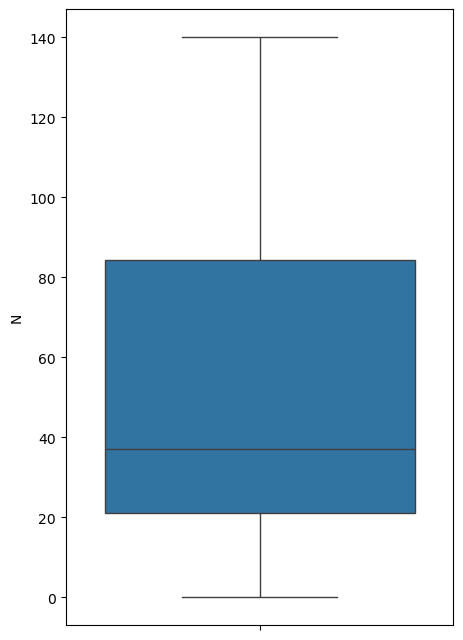

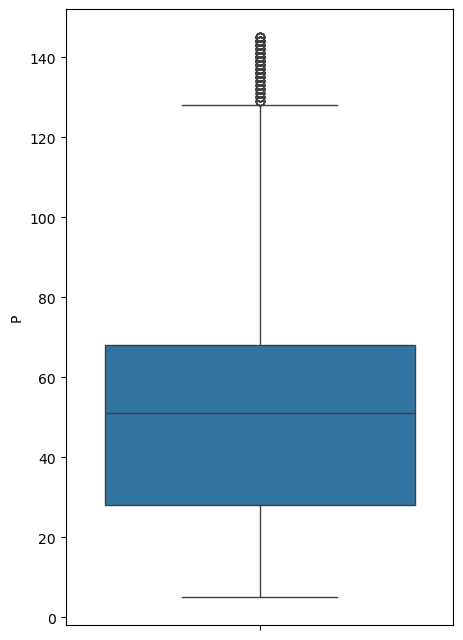

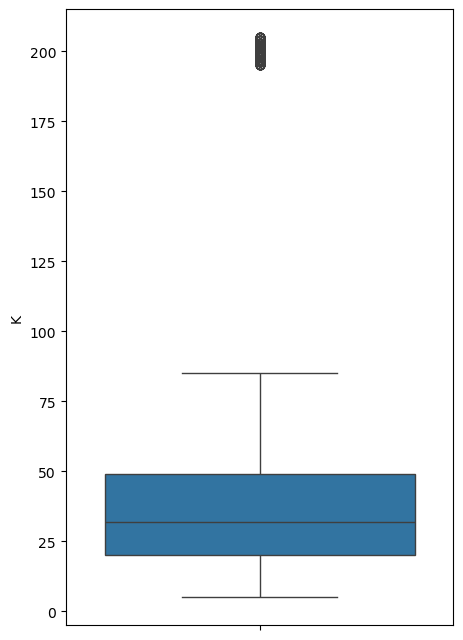

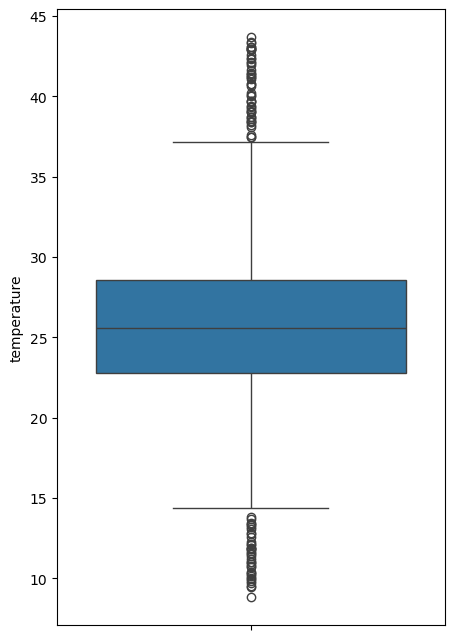

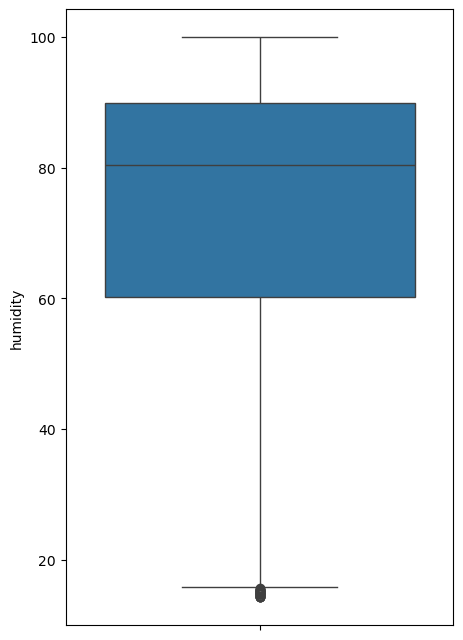

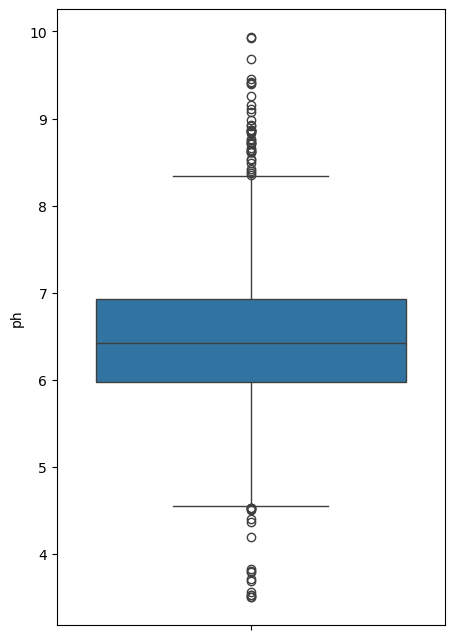

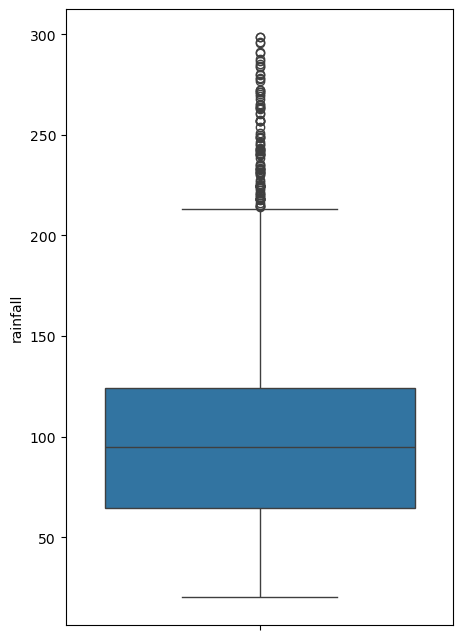

In [22]:
num_cols = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

for i in num_cols:
    plt.figure(figsize=(5, 8))
    sns.boxplot(y=df[i])

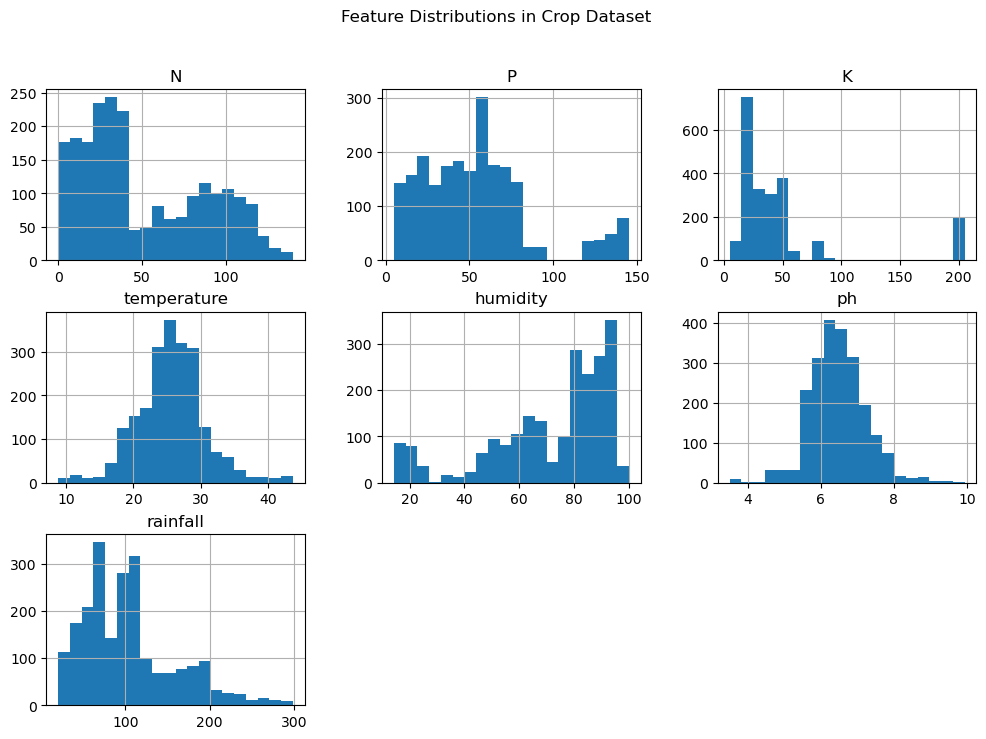

In [23]:
# distribution plot
df[num_cols].hist(figsize=(12,8), bins=20)
plt.suptitle("Feature Distributions in Crop Dataset")
plt.show()

In [24]:
# plt.figure(figsize=(15, 12))
# sns.pairplot(df[['N', 'P', 'K', 'temperature', 'humidity', 'label']], hue='label')
# plt.suptitle("Pairwise Relationship Between Soil & Weather Parameters")
# plt.show()


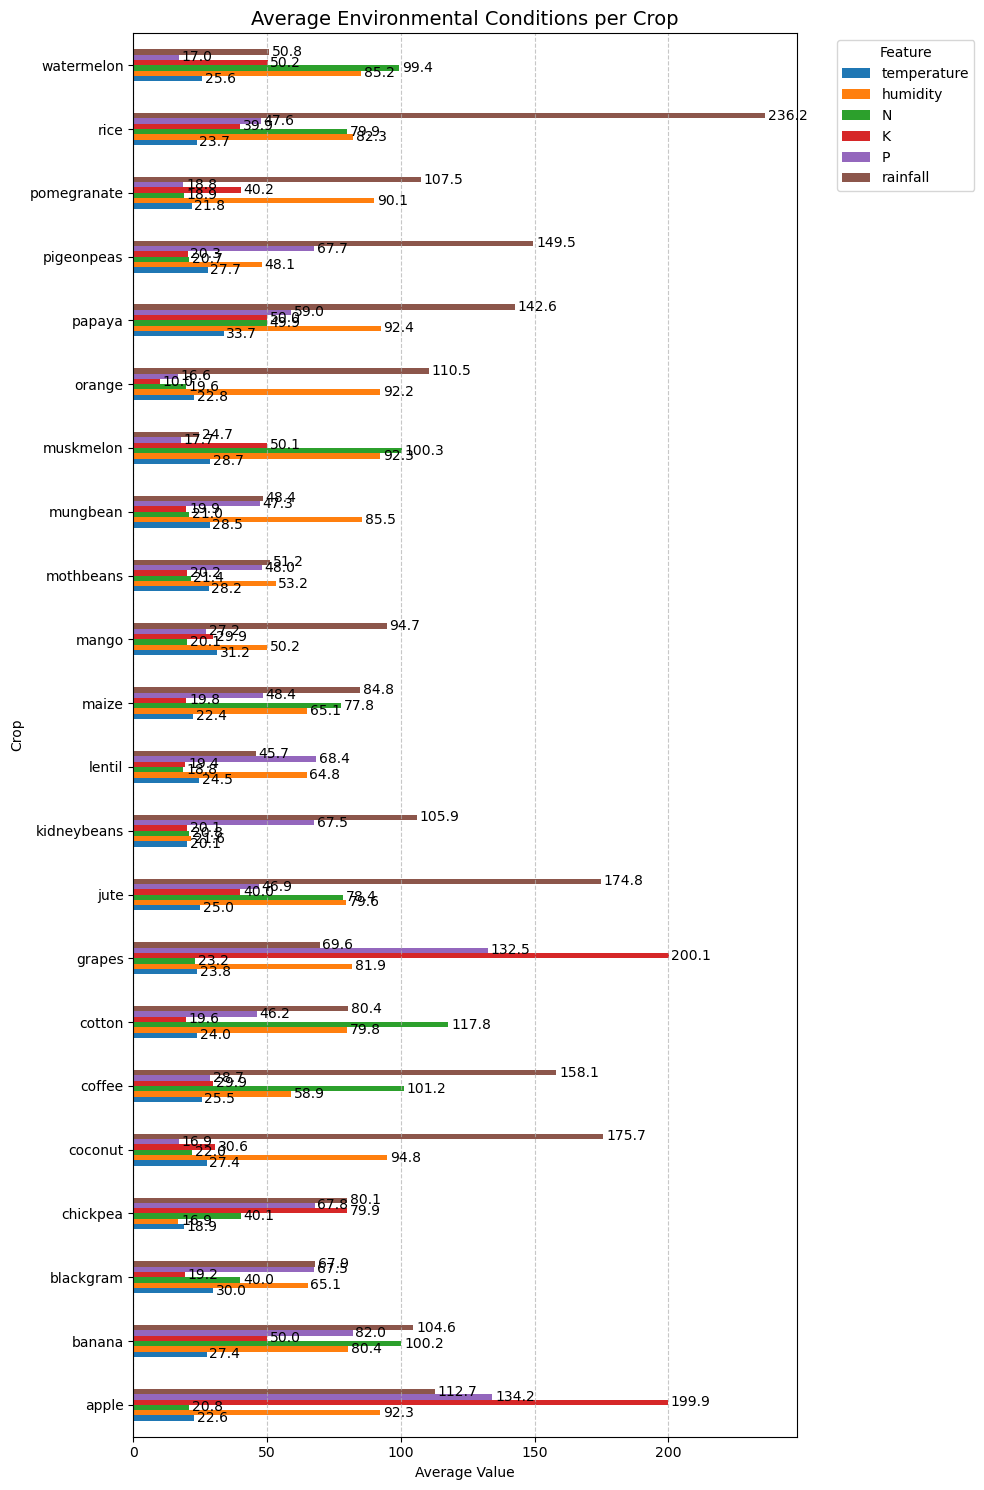

In [25]:
# climatic conditions per crop
avg_conditions = df.groupby('label')[['temperature', 'humidity',
       'N', 'K', 'P', 'rainfall']].mean().reset_index()

# Plot horizontally
ax = avg_conditions.plot(x='label', kind='barh', figsize=(10, 15))
plt.title("Average Environmental Conditions per Crop", fontsize=14)
plt.xlabel("Average Value")
plt.ylabel("Crop")
plt.legend(title="Feature", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Add value labels to bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", label_type='edge', padding=2)

plt.tight_layout()
plt.show()


In [26]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


### Class imbalance check

label
rice           100
maize          100
jute           100
cotton         100
coconut        100
papaya         100
orange         100
apple          100
muskmelon      100
watermelon     100
grapes         100
mango          100
banana         100
pomegranate    100
lentil         100
blackgram      100
mungbean       100
mothbeans      100
pigeonpeas     100
kidneybeans    100
chickpea       100
coffee         100
Name: count, dtype: int64


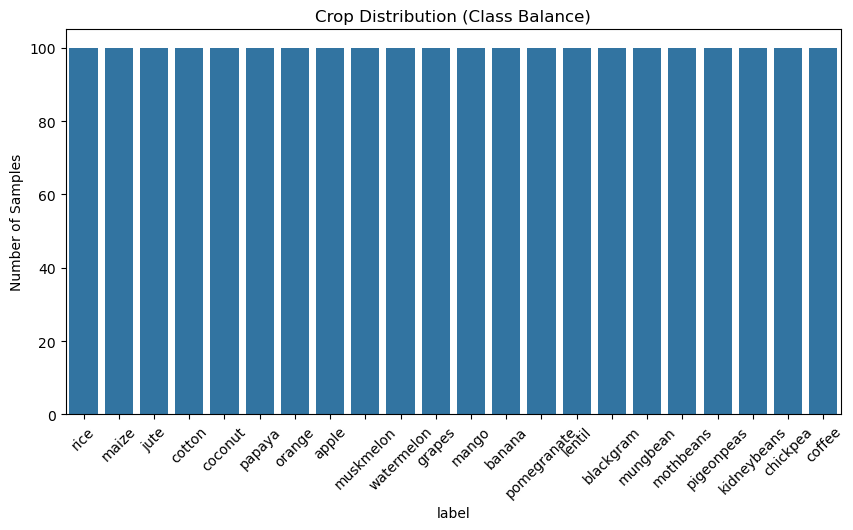

In [33]:
# Count occurrences
crop_distribution = df['label'].value_counts()

# Print class distribution
print(crop_distribution)

# Plot it
plt.figure(figsize=(10,5))
sns.barplot(x=crop_distribution.index, y=crop_distribution.values)
plt.title("Crop Distribution (Class Balance)")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.show()


### Model Building

In [36]:
df.columns

Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='object')

In [38]:
numerical_cols = ['temperature','ph', 'rainfall', 'N', 'K', 'P']

In [40]:
X = df.drop('label', axis=1)
y = df['label']
X

,N,P,K,temperature,humidity,ph,rainfall
0,90,42,43,20.879744,82.002744,6.502985,202.935536
1,85,58,41,21.770462,80.319644,7.038096,226.655537
2,60,55,44,23.004459,82.320763,7.840207,263.964248
3,74,35,40,26.491096,80.158363,6.980401,242.864034
4,78,42,42,20.130175,81.604873,7.628473,262.717340
...,...,...,...,...,...,...,...
2195,107,34,32,26.774637,66.413269,6.780064,177.774507
2196,99,15,27,27.417112,56.636362,6.086922,127.924610
2197,118,33,30,24.131797,67.225123,6.362608,173.322839
2198,117,32,34,26.272418,52.127394,6.758793,127.175293


In [42]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

In [44]:
# Encode target (Crop Type)
le_crop = LabelEncoder()
y = le_crop.fit_transform(y)


In [46]:
y

array([20, 20, 20, ...,  5,  5,  5])

In [48]:
from imblearn.over_sampling import BorderlineSMOTE

sm = BorderlineSMOTE(random_state=42, k_neighbors=2)
X_res, y_res = sm.fit_resample(X, y)

In [49]:
pd.Series(y_res).value_counts()

20    100
11    100
8     100
6     100
4     100
17    100
16    100
0     100
15    100
21    100
7     100
12    100
1     100
19    100
10    100
2     100
14    100
13    100
18    100
9     100
3     100
5     100
Name: count, dtype: int64

In [50]:
pd.Series(y_res).shape

(2200,)

In [54]:
X_res.shape

(2200, 7)

In [56]:
# Scale numerical columns
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_res)

In [58]:
# Split dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_res, test_size=0.2, random_state=42, stratify=y_res)

In [60]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, accuracy_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": SVC(),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "Gradient Boosting": GradientBoostingClassifier()
}

for name, clf in models.items():
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"{name}: {acc:.3f}")
    print(classification_report(y_test, y_pred, target_names=le_crop.classes_))

Logistic Regression: 0.973
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       0.95      1.00      0.98        20
    chickpea       1.00      1.00      1.00        20
     coconut       0.95      1.00      0.98        20
      coffee       1.00      1.00      1.00        20
      cotton       0.95      1.00      0.98        20
      grapes       1.00      1.00      1.00        20
        jute       0.83      1.00      0.91        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       0.94      0.85      0.89        20
       maize       1.00      0.95      0.97        20
       mango       0.95      1.00      0.98        20
   mothbeans       0.90      0.90      0.90        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      0.95      0.97        20


#### Random Forest

In [62]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=le_crop.classes_))

Accuracy: 0.9954545454545455
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        2

#### ANN

In [64]:
# num_classes = len(pd.Series(y_train).unique())

In [66]:
# import tensorflow as tf
# from tensorflow.keras.models import Sequential
# from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
# from tensorflow.keras.optimizers import Adam
# from tensorflow.keras.callbacks import EarlyStopping

# model = Sequential([
#     Dense(256, activation='relu', input_dim=X_train.shape[1]),
#     BatchNormalization(),
#     Dropout(0.2),
#     Dense(128, activation='relu'),
#     BatchNormalization(),
#     Dropout(0.2),
#     Dense(64, activation='relu'),
#     BatchNormalization(),
#     Dropout(0.2),
#     Dense(32, activation='relu'),
#     Dense(num_classes, activation='softmax')
# ])


# early_stop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)

# model.compile(optimizer=Adam(learning_rate=0.001),
#               loss='sparse_categorical_crossentropy',
#               metrics=['accuracy'])

# history = model.fit(X_train, y_train, epochs=200, batch_size=32, validation_split=0.2, callbacks=[early_stop])


In [68]:
# model.evaluate(X_test, y_test)

In [70]:
# import matplotlib.pyplot as plt

# # Assuming 'history' is the variable returned by model.fit()
# # e.g., history = model.fit(...)

# plt.figure(figsize=(10, 5))

# # Accuracy plot
# plt.plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
# plt.plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)

# plt.title('Training vs Validation Accuracy', fontsize=14)
# plt.xlabel('Epochs', fontsize=12)
# plt.ylabel('Accuracy', fontsize=12)
# plt.legend()
# plt.grid(True)
# plt.show()

# # Loss plot (optional but useful)
# plt.figure(figsize=(10, 5))
# plt.plot(history.history['loss'], label='Training Loss', linewidth=2)
# plt.plot(history.history['val_loss'], label='Validation Loss', linewidth=2)

# plt.title('Training vs Validation Loss', fontsize=14)
# plt.xlabel('Epochs', fontsize=12)
# plt.ylabel('Loss', fontsize=12)
# plt.legend()
# plt.grid(True)
# plt.show()

In [72]:
# y_pred = model.predict(X_test)
# y_pred

In [74]:
# y_pred.shape

In [78]:
# predict_probs = model.predict(X_test)

# top3_indices = np.argsort(predict_probs, axis=1)[:, -3:][:, ::-1]

# top3_crops = np.array(le_crop.classes_)[top3_indices]

# rec = []
# for i in range(len(predict_probs)):
#     if np.max(predict_probs, axis=1)[i] > 0.8:
#         rec.append([top3_crops[i][0]])
#     else:
#         rec.append(top3_crops[i])

# for i in range(5):
#     print(f"Sample {i + 1}.")
#     print(rec[i])

In [80]:
predict_probs = rf.predict_proba(X_test)

top3_indices = np.argsort(predict_probs, axis=1)[:, -3:][:, ::-1]

top3_crops = np.array(le_crop.classes_)[top3_indices]

rec = []
for i in range(len(predict_probs)):
    if np.max(predict_probs, axis=1)[i] > 0.8:
        rec.append([top3_crops[i][0]])
    else:
        rec.append(top3_crops[i])

for i in range(5):
    print(f"Sample {i + 1}.")
    print(rec[i])

Sample 1.
['orange']
Sample 2.
['banana']
Sample 3.
['cotton']
Sample 4.
['maize']
Sample 5.
['orange']


## Save best model - Random Forest

In [198]:
model.save("models/ann_model.keras")

In [413]:
import joblib

filename = "models/rf_model.pkl"
joblib.dump(rf, filename)

['models/rf_model.pkl']

In [82]:
import joblib

filename = "models/gb_model.pkl"
joblib.dump(models["Gradient Boosting"], filename)

['models/gb_model.pkl']

In [84]:
filename = "models/label_encoder.pkl"
joblib.dump(le_crop, filename)

['models/label_encoder.pkl']

In [86]:
filename = "models/scaler.pkl"
joblib.dump(scaler, filename)

['models/scaler.pkl']

In [662]:
df[df['label'] == 'rice']

,N,P,K,temperature,humidity,ph,rainfall,label
2,77,53,40,28.425080,77.596453,6.901847,112.807036,rice
9,94,50,37,25.665852,80.663850,6.948020,209.586971,rice
96,62,79,39,22.404186,82.046424,6.787440,225.234234,rice
118,76,79,42,23.497585,80.714686,6.721591,85.700882,rice
181,42,47,41,24.133590,81.554301,7.136405,90.973651,rice
...,...,...,...,...,...,...,...,...
7087,62,47,44,24.391893,86.480017,7.356376,186.747855,rice
7126,71,39,35,21.815899,82.752239,6.237632,115.682966,rice
7137,58,33,37,22.408971,79.896901,6.972430,202.733360,rice
7159,81,45,35,26.528728,80.122675,6.158377,218.916357,rice
